In [1]:
# Generate tax data
# Generate tax data with 100 points with only 1 slab such as income > 10000 with a tax of 20%.

"""
Generate synthetic tax data: 100 points, one tax slab.

Rule: income up to 10,000 is tax-free; income above 10,000 is taxed at 20%.
      tax = 0.20 * max(0, income - 10000)
"""

import numpy as np
import pandas as pd

N_POINTS = 100
THRESHOLD = 10_000
RATE = 0.20

rng = np.random.default_rng(seed=42)  # fixed seed so the data is reproducible

# Incomes spread on both sides of the threshold
income = rng.uniform(0, 30_000, N_POINTS).round(2)

# Tax applies only to the portion above the threshold
tax = (RATE * np.maximum(0, income - THRESHOLD)).round(2)

df = pd.DataFrame({"income": income, "tax": tax})
df.to_csv("tax_data.csv", index=False)

print(df.head(10))
print(f"\nRows: {len(df)}")
print(f"Rows with income > {THRESHOLD}: {(df.income > THRESHOLD).sum()}")
print("Saved to tax_data.csv")

     income      tax
0  23218.68  2643.74
1  13166.35   633.27
2  25757.94  3151.59
3  20921.04  2184.21
4   2825.32     0.00
5  29268.67  3853.73
6  22834.19  2566.84
7  23581.93  2716.39
8   3843.41     0.00
9  13511.58   702.32

Rows: 100
Rows with income > 10000: 67
Saved to tax_data.csv


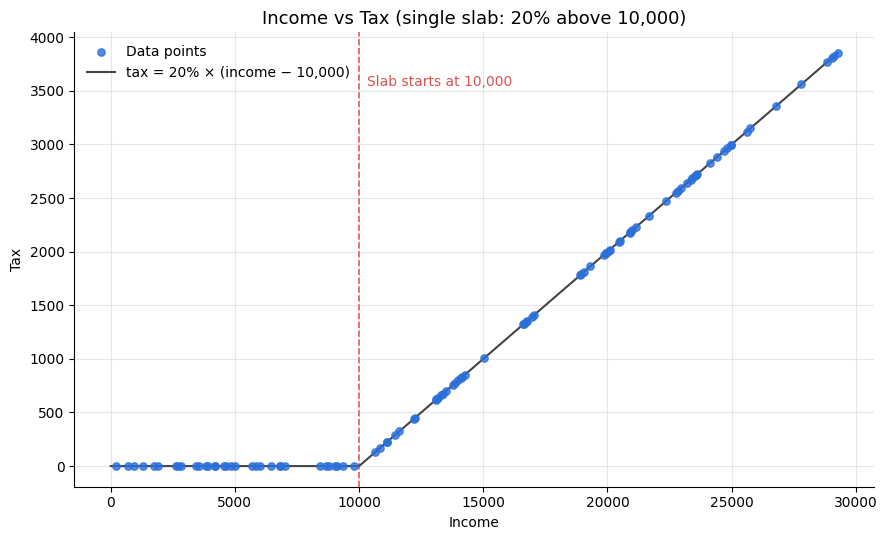

In [2]:
# write python code to visualize it
"""
Visualize the tax data from tax_data.csv: income vs tax, with the 10,000 slab marked.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

THRESHOLD = 10_000
RATE = 0.20

df = pd.read_csv("tax_data.csv")

fig, ax = plt.subplots(figsize=(9, 5.5))

# Data points
ax.scatter(df.income, df.tax, s=28, color="#2a6fdb", alpha=0.8, label="Data points", zorder=3)

# The true tax rule as a line
x = np.linspace(0, df.income.max(), 500)
ax.plot(x, RATE * np.maximum(0, x - THRESHOLD), color="#444", lw=1.5,
        label="tax = 20% × (income − 10,000)", zorder=2)

# Threshold marker
ax.axvline(THRESHOLD, color="#d9534f", ls="--", lw=1.2, zorder=1)
ax.text(THRESHOLD + 300, df.tax.max() * 0.92, "Slab starts at 10,000",
        color="#d9534f", fontsize=10)

ax.set_title("Income vs Tax (single slab: 20% above 10,000)", fontsize=13)
ax.set_xlabel("Income")
ax.set_ylabel("Tax")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left", frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.savefig("tax_plot.png", dpi=150)
plt.show()

In [ ]:
# Assignment: Try fitting in the logistic regression and notice the error.


In [5]:
def prediction(Income):
    if is_taxable(income):
        return compute_tax_taxable(income)
    return 0
